## <font color=#0099CC>mIAx - Taller Renta Fija - ANÁLISIS CARTERA DE RENTA FIJA</font>

En esta práctica, desarrollaremos un análisis exahustivo de un universo de Renta Fija, en concreto, de bonos corporativos. Además, construiremos y analizaremos varias carteras. 

Para ello, contaremos con la siguiente información almacenada en la carpeta *data*:
- **Universo de bonos**, con sus características esenciales (fichero *universo.csv*)
- **Histórico de precios** de cierre del universo de bonos anterior (fichero *precios_historicos_universo.csv*)
- **Curva de tipos de interés €STR** (fichero *curvaESTR.csv*)
- **Histórico de precios de otros índices** que nos serán de utilidad (fichero *precios_historicos_varios.csv*):
    - Índices de crédito: ITRAXX Main y ITRAXX XOVER. Serán útiles para la cobertura del riesgo de crédito.
    - Futuros sobre el *Schatz* (DU1), *BOBL* (OE1) y *BUND* (RX1). Serán útiles para la cobertura de los tipos de interés.
    - Índice de crédito *RECMTREU*, que valdría como benchmark de las carteras que construyamos.

No necesariamente se usará toda toda la información.

📣 <font color=#CC6600>**¡NORMAS!**</font>

La práctica se puede hacer en grupos de hasta **3 personas** y deberá entregarse antes del **26 de noviembre**. 

**ENTREGABLES**: 
* **Carpeta .zip** con el nombre del capitán del grupo.
* La carpeta debe mantener la estructura original.
* Los ficheros **funciones_aux.py** y **analisis_cartera.ipynb** deben completarse según se considere. 
* Deberán ser ejecutables y **enviarse ya debidamente ejecutados** y con los **resultados guardados**.
* Todo el **código debe estar comentado y razonado.**
* Las **celdas de texto deben responder explícitamente a las preguntas realizadas.**
* En la subcarpeta **"results" deberán estar los ficheros .csv** que se piden en los diferentes apartados.

Cada grupo expondrá una parte de los ejercicios en la clase del día 26, donde la resolveremos juntos a modo de taller. Esta exposición contará hasta **1 punto** de la nota final.
Cada apartado de esta práctica también contará hasta **1 punto** de la nota final.

Además, se valorará positivamente para la práctica la participación en las clases.

📣 <font color=#CC6600>**¡IMPORTANTE!**</font>

Todo el código implementado debe estar debidamente comentado e incluir conclusiones de los resultados obtenidos para optar a la máxima puntuación. Asimismo, se debe responder a las preguntas planteadas.

Las propuestas de mejora o posibles trabajos futuros se valorarán positivamente también.

Usa las fuentes de información que consideres necesarias para apoyar tus respuestas.

### <font color=#336699>Librerías</font>

In [41]:
import matplotlib.pyplot as plt
import pandas as pd
import datetime

In [42]:
# Estilo
plt.style.use('dark_background')

In [43]:
# Fecha de análisis
fecha_analisis = pd.to_datetime('2026-10-01')

### <font color=#336699>1. Datos</font>

**Análisis de datos.** En esta sección, haremos un análisis de la información que tenemos de cada bono y lo que significa. Asimismo, haremos los tratamientos y limpieza que necesitemos para luego poder usarlos.

Haz un primer análisis visual de la información que tenemos del universo de bono.
Entre otras, plantéate cuestiones como:
- ¿Divisas?
- ¿Tipo de bonos? ¿Fijo/Flotante? ¿Prelación? ¿Opcionalidad? ¿Hay bonos perpetuos?
- ¿Sectores? ¿Emisores? Si invirtéramos en todos los bonos, ¿dirías a priori que la cartera está diversificada?
- ¿Ratings? (Riesgo de crédito)
- ¿Otros datos cuantitativos?
    - Riesgo de liquidez - Horquillas y nominal vivo
- ¿Hay *gaps* en la información que vamos a tener que tratar?

**Guarda en "results" dos ficheros .csv:
1. "control_calidad_universo.csv" generado con la infomación del fichero universo.csv y que contenga las siguientes columnas para cada característica de los bonos:**
- número de observaciones
- número de datos *missing*
- número de valores únicos
- mínimo y máximo si aplica

2. "control_calidad_precios.csv" generado con la infomación del fichero precios_historicos_universo.csv y que para cada bono contenga las siguientes columnas:
- número de observaciones
- número de datos *missing*
- mínimo y máximo
- fecha inicio y fecha fin de cotización

Saca conclusiones de estas tablas de control. Identifica al menos 2 posibles problemas de calidad en estos dos ficheros que puedan afectar a los cálculos posteriores. Para cada uno, indica:
- problema
- tratamiento propuesto
- número de bonos afectados
- consecuencia de no tratarlo

In [44]:
import importlib
import os
import sys
from datetime import datetime



# Localizamos funciones_aux tanto desde src/ como desde la raíz del proyecto.
carpeta_src = "." if os.path.isfile("funciones_aux.py") else "src"
if carpeta_src not in sys.path:
    sys.path.insert(0, carpeta_src)

# Ejecutamos desde src/ (carpeta del notebook) o desde la raíz del proyecto.
carpeta_datos = "../data/" if os.path.isdir("../data") else "data/"

universo = pd.read_csv(carpeta_datos + "universo.csv", sep=";")


#### <font color=#808080>Divisas</font>

In [45]:
print(f"Diferentes dividas: {universo['Ccy'].value_counts()}")

Diferentes dividas: Ccy
EUR    2165
Name: count, dtype: int64


Como podemos observar el universo de bonos solo tiene una divisa, evitando que haya riesgo de divisa

#### <font color=#808080>Tipos de bono</font>

In [46]:
for campo in ["Coupon Type", "Coupon Frequency", "Seniority", "Callable"]:
    display(universo[campo].value_counts(dropna=False).rename("Emisiones"))

display(pd.Series({
    "Sin vencimiento contractual": universo["Maturity"].isna().sum(),
    "Cupón cero": universo["Coupon"].eq(0).sum(),
}))

Coupon Type
FIXED       1835
VARIABLE     330
Name: Emisiones, dtype: int64

Coupon Frequency
1    2156
2       9
Name: Emisiones, dtype: int64

Seniority
Sr Unsecured        1614
Sr Non Preferred     182
Sr Preferred         165
Subordinated         147
Jr Subordinated       24
Secured               20
1st lien              13
Name: Emisiones, dtype: int64

Callable
Y    1582
N     583
Name: Emisiones, dtype: int64

Sin vencimiento contractual    18
Cupón cero                     14
dtype: int64

Como podemos observar tenemos cupones de tipo fijo y flotante, dónde la mayoría son de tipo fijo, no encontramos bonos de tipo mixto, la frecuencia de los bonos es anual en 2156 casos en los 9 restantes es cada 6 meses. En cuanto al seniority encontramos que la mayoría son bonos Sr Unsecured. Hay 1582 bonos con opcionalidad. Finalmente hablando de los bonos con perpetuidad encontramos 18 bonos perpetuos y 14 de cupon 0

#### <font color=#808080>Sectores y emisores</font>

#### <font color=#808080>Ratings (Riesgo de crédito)</font>

In [47]:
RATINGS_IG = ("AAA", "AA+", "AA", "AA-", "A+", "A", "A-", "BBB+", "BBB", "BBB-")
RATINGS_HY = ("BB+", "BB", "BB-", "B+", "B", "B-", "CCC+", "CCC", "CCC-", "CC", "C", "D")

universo["Bucket"] = universo["Rating"].map(
    dict.fromkeys(RATINGS_IG, "IG") | dict.fromkeys(RATINGS_HY, "HY"),
).fillna("Sin rating")

tabla_ratings = pd.crosstab(universo["Rating"].fillna("Sin dato"), universo["Bucket"])

# Conservamos los ratings observados y dejamos al final los que están fuera de la escala.
orden_ratings = pd.Index(RATINGS_IG + RATINGS_HY)
ratings_en_escala = orden_ratings.intersection(tabla_ratings.index, sort=False)
otros_ratings = tabla_ratings.index.difference(orden_ratings, sort=False)
display(tabla_ratings.reindex(ratings_en_escala.append(otros_ratings)))

Bucket,HY,IG,Sin rating
AAA,0,4,0
AA+,0,6,0
AA,0,20,0
AA-,0,96,0
A+,0,180,0
A,0,222,0
A-,0,363,0
BBB+,0,415,0
BBB,0,300,0
BBB-,0,176,0


En cuanto al rating de los bonos podemos observar que la mayoría son bonos BBB+ encontrándose cerca de la línea diferencial entre HY e IG, también podemos observar que hay 372 bonos sin rating crediticio y 3 sin dato

#### <font color=#808080>Riesgo de liquidez - Horquillas y nominal vivo</font>

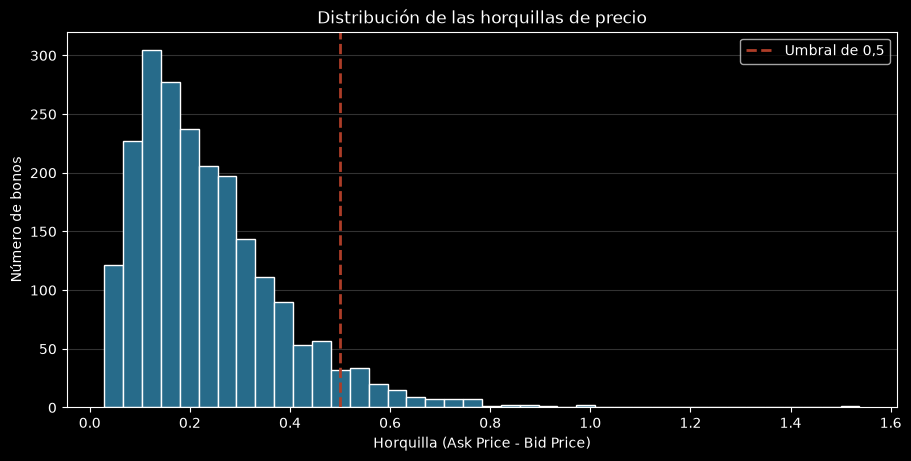

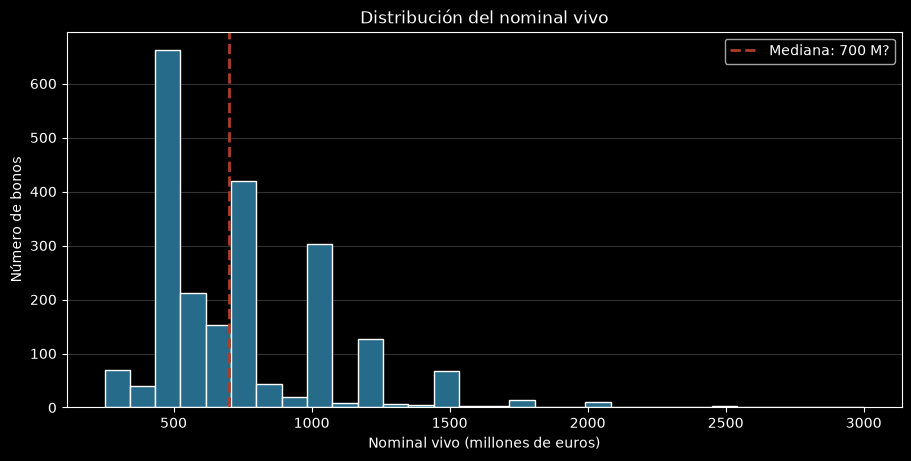

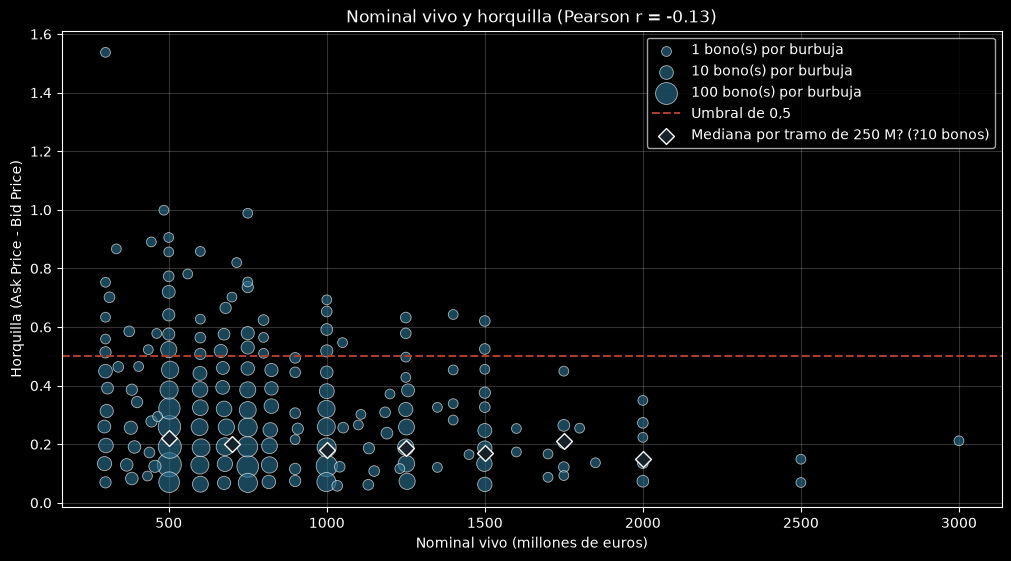

In [48]:
universo['Range'] = universo['Ask Price'] - universo['Bid Price']

# La horquilla se expresa en las mismas unidades que los precios.
horquillas = universo["Range"].dropna()
umbral = 0.5

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.hist(horquillas, bins=40, color="#276b8a", edgecolor="white")
ax.axvline(umbral, color="#ad3d28", linestyle="--", linewidth=2, label="Umbral de 0,5")
ax.set(title="Distribución de las horquillas de precio", xlabel="Horquilla (Ask Price - Bid Price)", ylabel="Número de bonos")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend()
plt.show()

nominal_vivo_millones = universo["Outstanding Amount"].dropna() / 1_000_000
mediana_nominal = nominal_vivo_millones.median()

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.hist(nominal_vivo_millones, bins=30, color="#276b8a", edgecolor="white")
ax.axvline(mediana_nominal, color="#ad3d28", linestyle="--", linewidth=2,
           label=f"Mediana: {mediana_nominal:.0f} M?")
ax.set(title="Distribución del nominal vivo",
       xlabel="Nominal vivo (millones de euros)", ylabel="Número de bonos")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend()
plt.show()

# Usamos solo los bonos con ambos datos disponibles.
datos_liquidez = universo[["Outstanding Amount", "Range"]].dropna()
nominal_millones = datos_liquidez["Outstanding Amount"] / 1_000_000
horquilla = datos_liquidez["Range"]
correlacion = nominal_millones.corr(horquilla)

umbral = 0.5
tramos = pd.cut(nominal_millones, bins=range(0, int(nominal_millones.max() // 250 + 1) * 250 + 1, 250))
medianas = (
    datos_liquidez.assign(Nominal=nominal_millones)
    .groupby(tramos, observed=True)
    .agg(Nominal=("Nominal", "median"), Horquilla=("Range", "median"),
         Bonos=("Range", "size"))
)
medianas = medianas[medianas["Bonos"] >= 10]

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")

# Cada burbuja se sit?a en el centro de los bonos de su grupo.
grupos = (
    pd.DataFrame({"Nominal": nominal_millones, "Horquilla": horquilla})
    .groupby([pd.cut(nominal_millones, 36), pd.cut(horquilla, 23)], observed=True)
    .agg(Nominal=("Nominal", "mean"), Horquilla=("Horquilla", "mean"),
         Bonos=("Horquilla", "size"))
    .sort_values("Bonos", ascending=False)
)
tamanos = 28 + 22 * grupos["Bonos"] ** 0.5
estilo_burbujas = dict(color="#276b8a", alpha=0.65, edgecolors="white", linewidths=0.6)
burbujas = ax.scatter(grupos["Nominal"], grupos["Horquilla"], s=tamanos, **estilo_burbujas)
for cantidad in (1, 10, 100):
    ax.scatter([], [], s=28 + 22 * cantidad ** 0.5,
               label=f"{cantidad} bono(s) por burbuja", **estilo_burbujas)
ax.axhline(umbral, color="#ad3d28", linestyle="--", linewidth=1.5,
           label="Umbral de 0,5")
ax.scatter(medianas["Nominal"], medianas["Horquilla"], marker="D", s=65,
           color="#17212b", edgecolors="white", linewidths=1, zorder=4,
           label="Mediana por tramo de 250 M? (?10 bonos)")
ax.set(title=f"Nominal vivo y horquilla (Pearson r = {correlacion:.2f})",
       xlabel="Nominal vivo (millones de euros)",
       ylabel="Horquilla (Ask Price - Bid Price)")
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="upper right")
plt.show()

Asumiendo que 0.5 o 50 pb es lo que consideraríamos como una diferencia sustancial para interpretar que un bono no es líquido podemos ver en el diagrama que la gran mayoría se encuentran dentro de la horquilla. El nominal vivo mediano es de 700 millones de euros. El gráfico muestra que las emisiones con mayor nominal vivo tienden a presentar horquillas algo más estrechas, aunque hay bastante dispersión. Esto sugiere que un mayor nominal vivo puede favorecer la liquidez, pero por sí solo confirma poco sobre las diferencias de horquilla entre bonos.

#### Tratamiento de los bonos con fecha de call vencida

El taller supone que el emisor ejerce el *call*. Para la valoración del 1 de octubre de 2026, marcamos como `RescatadoAsumido` los bonos rescatables cuya fecha de call es igual o anterior a la fecha de valoración y anterior al vencimiento contractual, si existe. Hay 11 bonos en este caso, incluido el perpetuo `FR0014005EJ6`, cuyo call era el 16 de septiembre de 2026.

Estos bonos se conservan en el universo y en `results`, junto con el precio de mercado del CSV. Bajo la hipótesis de rescate, ya no quedan flujos pendientes y se registran a cero el precio limpio, el precio sucio y el cupón corrido. Las diferencias quedan vacías porque la cotización original no es comparable con una posición ya amortizada y la diferencia porcentual tendría un denominador cero.

In [49]:
fecha_valor = pd.Timestamp("2026-10-01")

# Marcamos los bonos cuyo rescate se supone ejercido a la fecha de valoración.
fechas_call = pd.to_datetime(universo["Next Call Date"], format="%d/%m/%Y")
fechas_vencimiento = pd.to_datetime(universo["Maturity"], format="%d/%m/%Y")
universo["RescatadoAsumido"] = (
    universo["Callable"].eq("Y")
    & fechas_call.le(fecha_valor)
    & (fechas_vencimiento.isna() | fechas_call.lt(fechas_vencimiento))
)

#### <font color=#808080>Resto de información</font>

En esta sección, analizamos el resto de ficheros para ver qué información tenemos y, en caso de haber *gaps*, limpiar los datos antes de trabajar con ellos.

##### <font color=#CC6600>Precios bonos universo</font>

In [50]:
precios_historicos_universo = pd.read_csv(
    carpeta_datos + "precios_historicos_universo.csv",
    sep=";",
    index_col=0,
    na_values=["#N/D"],
)

precios_historicos_universo.columns = pd.to_datetime(precios_historicos_universo.columns, format="%d/%m/%Y")
precios_laborables = precios_historicos_universo.loc[:, precios_historicos_universo.columns.day_of_week < 5]

precios_laborables

,2023-10-02,2023-10-03,2023-10-04,2023-10-05,2023-10-06,2023-10-09,2023-10-10,2023-10-11,2023-10-12,2023-10-13,...,2026-09-18,2026-09-21,2026-09-22,2026-09-23,2026-09-24,2026-09-25,2026-09-28,2026-09-29,2026-09-30,2026-10-01
XS0161488498 Corp,126.450,126.000,125.939,126.330,126.117,126.964,127.079,127.549,127.434,127.706,...,117.81400,118.24270,118.16530,117.43060,117.24110,117.38740,117.09530,117.00470,117.39170,117.87400
FR0000471930 Corp,130.386,129.697,129.448,129.795,129.554,130.564,130.672,131.247,131.085,131.493,...,121.30710,121.70810,121.63900,120.83860,120.61920,120.77240,120.50200,120.57260,120.94610,121.40000
XS0162513211 Corp,110.900,110.567,110.719,111.117,111.036,111.869,111.791,112.165,111.707,112.007,...,108.09520,108.53080,108.44040,107.77730,107.64940,107.77690,107.50300,107.64300,108.02480,108.39250
XS0162869076 Corp,112.493,112.127,111.844,112.191,112.051,112.892,112.762,113.094,112.796,113.125,...,108.32050,108.71740,108.67100,107.94760,107.63190,107.67910,107.22920,107.29920,107.67610,108.11550
FR0010014845 Corp,108.291,107.608,108.047,108.480,108.277,109.125,109.598,109.792,109.014,109.057,...,104.30030,104.64700,104.65000,103.93390,103.43700,103.58160,103.33920,103.49610,103.71320,102.04670
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XS2724401588 Corp,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,103.29470,103.39430,103.32530,103.10310,102.87050,102.78500,102.64310,102.68350,102.66050,102.49230
XS2731506841 Corp,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,98.04066,98.37811,98.33232,97.74440,97.60364,97.68257,97.47356,97.56927,97.88131,98.15771
FR001400MLN4 Corp,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,99.24871,99.52154,99.48908,99.02680,98.88933,98.95573,98.74598,98.79104,98.99728,99.25401
XS2732952838 Corp,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,99.28577,99.42289,99.39642,99.18390,99.17272,99.25793,99.21144,99.23556,99.41426,99.64713


Como observamos de este archivo hay bastantes valores que son #N/D, esto puede ser por distintas situaciones: que el bono no esté en circulación, que haya un valor correspondiente a día no laborable, por festivo o por ser fin de semana, que el proveedor empezó a dar información del bono tarde o dejará de publicar sus precios. La mayoría de los

##### <font color=#CC6600>Otros precios</font>

Para terminar con el análisis de datos, falta lo leído en los ficheros de *precios_historicos_varios.csv* y *curvaESTR.csv*.

In [51]:
curva_estr = pd.read_csv(carpeta_datos + "curvaESTR.csv", sep=";")
curva_estr.isna().sum()

Date           0
Market Rate    1
Zero Rate      1
Discount       0
dtype: int64

De la interpretación de la curva estr obtenemos que no hay valores nulos salvando los indicados en la fecha actual supuesta 1 de Octubre de 2026, que no afectan a la interpretación

##### Cotizaciones para los rebalanceos mensuales

Alineamos el histórico de bonos y el RECMTREU por fecha. Para cada mes elegimos la primera sesión con datos en ambos ficheros y normalizamos los identificadores del histórico a ISIN. En cada corte usamos el MID del día y, si falta, el último MID disponible desde la sesión común anterior. Filtramos las cotizaciones previas a la emisión antes de rellenar los huecos. Los huecos más antiguos quedan vacíos.

La regla cubre **147 observaciones**, entre ellas **69** el 1 de mayo de 2024 y **72** el 1 de mayo de 2025. Los ficheros no indican la causa de cada hueco. Preparamos una tabla mensual específica para el apartado 5 y conservamos el histórico diario para comprobar las salidas y valorar posiciones sin MID reciente.

In [ ]:
from pathlib import Path

import backtest

importlib.reload(backtest)

historicos_varios = pd.read_csv(
    Path(carpeta_datos) / "precios_historicos_varios.csv",
    sep=";",
    index_col=0,
    na_values=["#N/D"],
)
benchmark_recmtreu = historicos_varios["RECMTREU Index"].dropna()
benchmark_recmtreu.index = pd.to_datetime(benchmark_recmtreu.index, format="%d/%m/%Y")

precios_mid_backtest = precios_laborables.copy()
precios_mid_backtest.index = precios_mid_backtest.index.str.split().str[0]
precios_mid_rebalanceo = backtest.preparar_precios_rebalanceo(
    universo, precios_mid_backtest, benchmark_recmtreu
)

# Contamos los huecos cubiertos sin sobrescribir las cotizaciones originales.
mid_del_dia = precios_mid_backtest.loc[:, precios_mid_rebalanceo.columns]
huecos_cubiertos = (mid_del_dia.isna() & precios_mid_rebalanceo.notna()).sum()
display(huecos_cubiertos[huecos_cubiertos.gt(0)].to_frame("MID recuperados"))

,MID recuperados
2024-04-02,5
2024-05-01,69
2024-07-01,1
2025-05-01,72


#### <font color=#808080>Conclusiones</font>

### <font color=#336699>2. Valoración</font>

**Valoración de los bonos del universo** utilizando la curva de descuento y bajo ciertas asunciones. Comparación de estos precios con los precios de mercado.

En esta sección, valoraremos los bonos utilizando la curva. Para ello, crea una función (puedes hacerlo en un .py aparte) que con las **características del bono, la curva y un spread de crédito** para que devuelva la valoración del bono (incluyendo **precio limpio, cupón corrido y precio sucio**).

Si asumimos que el **spread de crédito es 0**, y la ejecutamos para el 01/10/2026:
- ¿Qué observas si comparas los precios obtenidos y los precios de mercado? 
- ¿Crees que la diferencia se debe a un factor relacionado sólo con el riesgo crediticio?
- ¿Qué otros factores influyen en ese spread?

Para la valoración, haz las siguientes simplificaciones:

- Asume que el vencimiento de los bonos perpetuos (para los que no hay vencimiento) es la próxima fecha call.
- Asume que todos aquellos bonos que tengan call serán calleados. Por lo tanto, usa la fecha call como fecha de vencimiento.
- Asume que los cupones son fijos hasta vencimiento (aunque alguno cambie a lo largo de la vida del bono).
- Usa la base de cálculo ACT/365. No tengas en cuenta la convención de día hábil.

Ten en cuenta que necesitarás una función de interpolación también. Interpola los factores de descuento exponencialmente.

**Guarda en "results" una tabla llamada "valoracion.csv" que contenga:**

- ISIN
- PrecioMercado
- PrecioSucioCalculado
- CuponCorrido
- PrecioLimpioCalculado
- DiferenciaMecadoCalculo
- DiferenciaPct


In [52]:
import funciones_aux

# Recarga los cambios guardados del módulo antes de obtener las funciones para evitar tener que reiniciar el kernel del notebook.
importlib.reload(funciones_aux)
from funciones_aux import valoracion_bono

primera = curva_estr["Discount"].notna().to_numpy().nonzero()[0][0]

curva_descuento = curva_estr.iloc[primera:, [0, 3]].copy()
curva_descuento.columns = ["fecha", "factor_descuento"]

curva_descuento["fecha"] = pd.to_datetime(
    curva_descuento["fecha"],
    format="%d/%m/%Y",
)

flujos_por_isin = {}


def valorar_fila(bono):
    precio_mercado = bono["Price"]
    if bono["RescatadoAsumido"]:
        precio_limpio = precio_sucio = cupon_corrido = 0.0
        diferencia = diferencia_pct = float("nan")
        flujos = None
    else:
        precio_limpio, precio_sucio, cupon_corrido, flujos = valoracion_bono(
            bono,
            curva_descuento,
            fecha_valor=fecha_valor,
            nominal=100,
            spread=0,
        )
        diferencia = precio_mercado - precio_limpio
        diferencia_pct = diferencia / precio_limpio

    flujos_por_isin[bono["ISIN"]] = flujos

    return pd.Series({
        "ISIN": bono["ISIN"],
        "PrecioMercado": precio_mercado,
        "PrecioSucioCalculado": precio_sucio,
        "CuponCorrido": cupon_corrido,
        "PrecioLimpioCalculado": precio_limpio,
        "DiferenciaMercadoCalculo": diferencia,
        "DiferenciaPct": diferencia_pct,
    })

results = universo.apply(valorar_fila, axis=1)
display(results)

,ISIN,PrecioMercado,PrecioSucioCalculado,CuponCorrido,PrecioLimpioCalculado,DiferenciaMercadoCalculo,DiferenciaPct
0,XS0161488498,117.87400,129.005186,5.136986,123.868200,-5.994200,-0.048392
1,FR0000471930,121.40000,132.906579,5.476027,127.430552,-6.030552,-0.047324
2,XS0162513211,108.39250,117.715137,3.607534,114.107603,-5.715103,-0.050085
3,XS0162869076,108.11550,118.503744,3.685959,114.817785,-6.702285,-0.058373
4,FR0010014845,102.04670,116.909909,0.197260,116.712649,-14.665949,-0.125659
...,...,...,...,...,...,...,...
2160,XS2724401588,102.49230,110.829376,5.919178,104.910198,-2.417898,-0.023047
2161,XS2731506841,98.15771,105.520240,3.061644,102.458596,-4.300886,-0.041977
2162,FR001400MLN4,99.25401,106.771865,3.322603,103.449262,-4.195252,-0.040554
2163,XS2732952838,99.64713,103.290226,2.718493,100.571733,-0.924603,-0.009193


### <font color=#336699>3. Spread</font>

**Cálculo del z-spread** que pagan los bonos sobre la curva.

Calculemos ahora los spreads que debemos añadir a la curva con un movimiento paralelo para que cuadren los precios de mercado que tenemos. Para ello, usa la función de valoración del apartado anterior. 
- ¿Qué observas? ¿Tienen sentido los resultados? 
- ¿Con qué datos de los que tenemos compararías para ver si los resultados son coherentes?

**Guarda en "results" una tabla llamada "spread.csv" que contenga:**

- ISIN
- Spread
- PrecioSpreadCero
- PrecioSpreadCalculado

In [53]:
from pathlib import Path


def spread_fila(fila):
    return funciones_aux.calcular_spread(
        flujos_por_isin[fila["ISIN"]],
        precio_mercado=fila["PrecioMercado"],
        precio_limpio=fila["PrecioLimpioCalculado"],
        cupon_corrido=fila["CuponCorrido"],
    )


calculados = results.apply(spread_fila, axis=1, result_type="expand")

results_spread = pd.DataFrame({
    "ISIN": results["ISIN"],
    "Spread": calculados[0],
    "PrecioSpreadCero": results["PrecioLimpioCalculado"],
    "PrecioSpreadCalculado": calculados[1],
})

carpeta_results = Path(carpeta_datos).resolve().parent / "results"
carpeta_results.mkdir(exist_ok=True)
results_spread.to_csv(carpeta_results / "spread.csv", index=False)
display(results_spread)

,ISIN,Spread,PrecioSpreadCero,PrecioSpreadCalculado
0,XS0161488498,92.355442,123.868200,117.87400
1,FR0000471930,90.989170,127.430552,121.40000
2,XS0162513211,92.215817,114.107603,108.39250
3,XS0162869076,108.223211,114.817785,108.11550
4,FR0010014845,225.733893,116.712649,102.04670
...,...,...,...,...
2160,XS2724401588,197.325827,104.910198,102.49230
2161,XS2731506841,89.120595,102.458596,98.15771
2162,FR001400MLN4,111.139788,103.449262,99.25401
2163,XS2732952838,48.164706,100.571733,99.64713


### <font color=#336699>4. Yield, Duración, Convexidad</font>

Cálculo de **yield, duración y convexidad**.

Calculemos ahora la siguiente información, también relacionada con la rentabilidad y riesgo de las emisiones:
- *Yield* - Por simplicidad, en este caso, en el caso de los bonos callable, nos quedaremos con la fecha call, como en el ejercicio anterior. Usa las mismas asunciones que para la valoración y el spread.
- Duración
- Convexidad

Responde a las siguientes preguntas:
- ¿Que relación hay entre la *yield* calculada y el spread calculado en el apartado anterior?
- ¿Qué relación hay entre la duración y el vencimiento? ¿Qué refleja la duración? ¿De qué otra forma se podría obtener esta sensibilidad?
- Estima la variación del precio de los bonos ante una caída de un 1% de la *yield* usando la duración y convexidad, ¿qué observas?

**Guarda en "results" una tabla llamada "sensibilidad.csv" que contenga:**

- ISIN
- Yield
- Dur
- ModDur
- Convexidad
- VarPrecioDurConv

In [54]:
from pathlib import Path

frecuencias = universo.set_index("ISIN")["Coupon Frequency"]


def yield_fila(fila):
    isin = fila["ISIN"]
    return funciones_aux.calcular_yield(
        flujos_por_isin[isin],
        precio_sucio_mercado=fila["PrecioMercado"] + fila["CuponCorrido"],
        frecuencia=int(frecuencias.loc[isin]),
    )


def sensibilidad_fila(fila):
    isin = fila["ISIN"]
    return funciones_aux.calcular_sensibilidad(
        flujos_por_isin[isin],
        y=fila["Yield"],
        frecuencia=int(frecuencias.loc[isin]),
    )


results_yield = results[["ISIN"]].assign(Yield=results.apply(yield_fila, axis=1))
results_yield[["Dur", "ModDur", "Convexidad"]] = results_yield.apply(
    sensibilidad_fila, axis=1, result_type="expand"
)

# Sensibilidad monetaria por cada 100 de nominal, antes de escalar por el shock.
precio_sucio_mercado = results["PrecioMercado"] + results["CuponCorrido"]
results_yield["MoneyDuration"] = results_yield["ModDur"] * precio_sucio_mercado
# Caída aproximada del precio por cada 100 de nominal al subir la yield 1 pb.
results_yield["PVBP"] = results_yield["MoneyDuration"] * 1e-4

# VarPrecioDurConv se expresa como porcentaje del precio sucio (p. ej. 5.0 = 5 %).
cambio_yield = -0.01
results_yield["VarPrecioDurConv"] = 100 * (
    -results_yield["ModDur"] * cambio_yield
    + 0.5 * results_yield["Convexidad"] * cambio_yield**2
)

carpeta_results = Path(carpeta_datos).resolve().parent / "results"
carpeta_results.mkdir(exist_ok=True)
results_yield.to_csv(carpeta_results / "sensibilidad.csv", index=False)
display(results_yield)

,ISIN,Yield,Dur,ModDur,Convexidad,MoneyDuration,PVBP,VarPrecioDurConv
0,XS0161488498,0.042080,5.137244,4.929797,32.568468,606.419240,0.060642,5.092640
1,FR0000471930,0.041929,5.088864,4.884078,32.186650,619.672440,0.061967,5.045011
2,XS0162513211,0.042122,5.384131,5.166509,34.792824,578.649136,0.057865,5.340473
3,XS0162869076,0.043788,5.363882,5.138863,34.511660,574.532424,0.057453,5.311422
4,FR0010014845,0.056312,5.901611,5.586995,39.752442,571.236477,0.057124,5.785757
...,...,...,...,...,...,...,...,...
2160,XS2724401588,0.050052,1.117284,1.064027,2.201587,115.352708,0.011535,1.075035
2161,XS2731506841,0.041475,4.662960,4.477266,25.892523,453.185927,0.045319,4.606728
2162,FR001400MLN4,0.043317,3.602490,3.452919,16.026360,354.188785,0.035419,3.533051
2163,XS2732952838,0.035663,1.866705,1.802426,5.093544,184.506465,0.018451,1.827894


Añadido al análisis de las sensibilidades introducimos el MoneyDuration ya que es una expresión que nos permite calcular el cambio en términos monetarios de un bono en función del cambio de la YTM. Es decir para un ejemplo en el que la MoneyDuration sea 606.419240, querrá decir que si ya YTM se mueve 1pb el precio se movería un 0,0606 €

Añadido al análisis de las sensibilidades introducimos el MoneyDuration ya que es una expresión que nos permite calcular el cambio en términos monetarios de un bono en función del cambio de la YTM. Es decir para un ejemplo en el que la MoneyDuration sea 606.419240, querrá decir que si ya YTM se mueve 1pb el precio se movería un 0,0606 €

### <font color=#336699>5. Cartera equiponderada</font>

**Contrucción de una cartera equiponderada** con todos los bonos del universo. Contraste con el benchmark (os proponemos el índice RECMTREU para el que os hemos dado los precios) y backtest de la estrategia. ¡OJO! El índice es *Total Return*.

Crea un algoritmo de inversión que consista en una cartera equiponderada, asignando el mismo peso a todos los bonos vivos en cada fecha de rebalanceo.

Asume rebalanceo mensual, y que no tenemos costes más allá de los implícitos en el propio precio. Calcula la evolución que hubiese tenido tu algoritmo. Por simplificación, utiliza los precios MID que se te dan.

- ¿Qué sería lo más correcto en lugar de utilizar los precios MID?
- ¿Se te ocurre algún otro benchmark que se podría utilizar?

**Guarda en "results" una tabla llamada "backtest_equal_weight.csv" que contenga:**

- Fecha Mes
- Rent cartera
- Rent benchmark
- Dif


In [ ]:
# Usamos los MID mensuales y el benchmark preparados en el punto 1.
backtest_cartera, pesos_cartera = backtest.backtest_equiponderado(
    universo, precios_mid_backtest, benchmark_recmtreu,
    precios_rebalanceo=precios_mid_rebalanceo,
)

carpeta_results = Path(carpeta_datos).resolve().parent / "results"
carpeta_results.mkdir(exist_ok=True)
backtest_cartera.to_csv(carpeta_results / "backtest_equal_weight.csv", index=False)

# Cada fila de pesos_cartera contiene las posiciones al inicio del periodo.
display(pesos_cartera.gt(0).sum(axis=1).to_frame("Bonos en cartera"))
evolucion_cartera = backtest_cartera.assign(
    **{
        "Cartera base 100": 100 * (1 + backtest_cartera["Rent cartera"]).cumprod(),
        "RECMTREU base 100": 100 * (1 + backtest_cartera["Rent benchmark"]).cumprod(),
    }
)
display(evolucion_cartera)

,Bonos en cartera
Fecha rebalanceo,
2023-10-02,2078
2023-11-01,2097
2023-12-01,2153
2024-01-02,2165
2024-02-01,2165
2024-03-01,2165
2024-04-02,2165
2024-05-01,2165
2024-06-03,2165


,Fecha Mes,Rent cartera,Rent benchmark,Dif,Cartera base 100,RECMTREU base 100
0,2023-11-01,0.010213,0.008975,0.001238,101.021305,100.897546
1,2023-12-01,0.034953,0.025753,0.009200,104.552331,103.495976
2,2024-01-02,0.025621,0.019919,0.005702,107.231065,105.557528
3,2024-02-01,0.002364,0.003257,-0.000893,107.484553,105.901354
4,2024-03-01,-0.009350,-0.007991,-0.001359,106.479596,105.055073
5,2024-04-02,0.010982,0.008691,0.002291,107.648937,105.968120
6,2024-05-01,-0.008032,-0.005858,-0.002174,106.784291,105.347366
7,2024-06-03,0.005839,0.005745,0.000094,107.407761,105.952553
8,2024-07-01,0.001081,0.001790,-0.000709,107.523884,106.142248
9,2024-08-01,0.025254,0.021526,0.003728,110.239249,108.427046


,Rentabilidad acumulada (%),Rentabilidad anualizada (%),Volatilidad anualizada (%),Caída máxima (%)
Cartera equiponderada,15.62,4.96,3.65,1.45
RECMTREU TR,12.90,4.13,3.20,2.34


,Tracking error anualizado (%),Ratio de información,Meses por delante,Meses observados
0,0.8,1.01,19,36


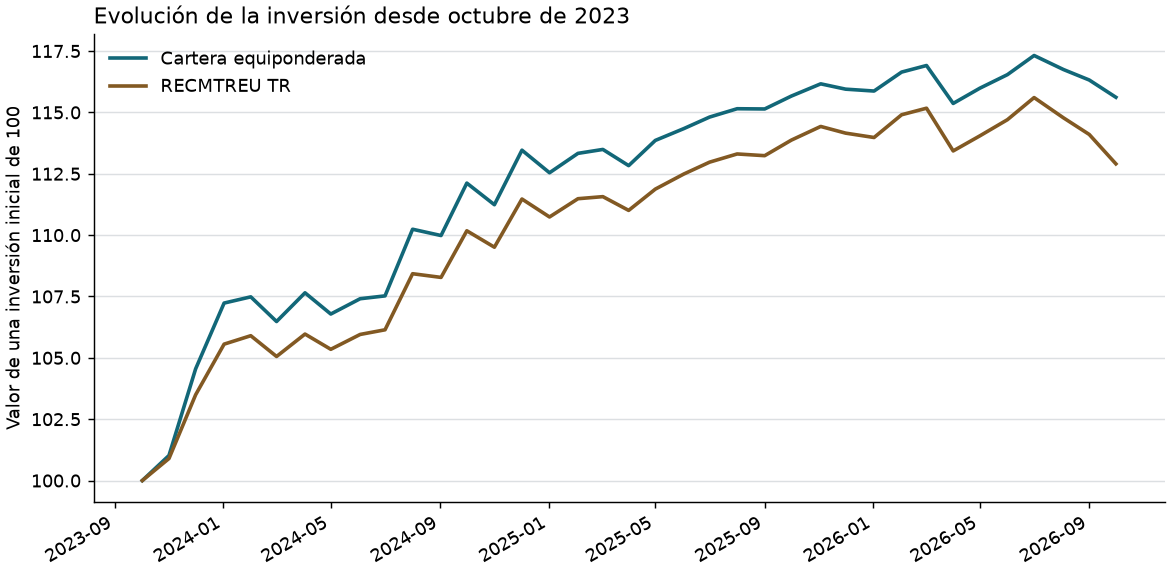

In [ ]:
from math import sqrt

import matplotlib.pyplot as plt

rent_mensual = backtest_cartera.set_index("Fecha Mes")[
    ["Rent cartera", "Rent benchmark"]
].rename(columns={"Rent cartera": "Cartera equiponderada", "Rent benchmark": "RECMTREU TR"})

base_100 = evolucion_cartera.set_index("Fecha Mes")[
    ["Cartera base 100", "RECMTREU base 100"]
].set_axis(rent_mensual.columns, axis=1)
base_100.loc[pesos_cartera.index[0]] = 100.0
base_100 = base_100.sort_index()

meses = len(rent_mensual)
factor_acumulado = base_100.iloc[-1] / 100
caida_desde_maximo = 1 - base_100 / base_100.cummax()
metricas_ejercicio_5 = pd.DataFrame({
    "Rentabilidad acumulada (%)": 100 * (factor_acumulado - 1),
    "Rentabilidad anualizada (%)": 100 * (factor_acumulado ** (12 / meses) - 1),
    "Volatilidad anualizada (%)": 100 * rent_mensual.std() * sqrt(12),
    "Caída máxima (%)": 100 * caida_desde_maximo.max(),
})

diferencia_mensual = backtest_cartera["Dif"]
tracking_error = diferencia_mensual.std() * sqrt(12)
ratio_informacion = 12 * diferencia_mensual.mean() / tracking_error
metricas_activas = pd.DataFrame([{
    "Tracking error anualizado (%)": 100 * tracking_error,
    "Ratio de información": ratio_informacion,
    "Meses por delante": int(diferencia_mensual.gt(0).sum()),
    "Meses observados": meses,
}])

display(metricas_ejercicio_5.round(2))
display(metricas_activas.round(2))

fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
base_100.plot(ax=ax, color=["#126778", "#825923"], linewidth=2)
ax.set_title("Evolución de la inversión desde octubre de 2023", loc="left")
ax.set_ylabel("Valor de una inversión inicial de 100")
ax.set_xlabel("")
ax.grid(axis="y", color="#dcdfe2", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

#### Resultado del backtest

En los 36 periodos mensuales, la cartera acumula un **15,62 %** frente al **12,90 %** del RECMTREU Total Return. La diferencia acumulada es de **2,71 puntos porcentuales**. La rentabilidad anualizada es del **4,96 %** para la cartera y del **4,13 %** para el índice. La cartera queda por delante en **19 de los 36 meses**.

La volatilidad anualizada es del **3,65 %** para la cartera y del **3,20 %** para el índice. La caída máxima en cierres mensuales es del **1,45 %** para la cartera y del **2,34 %** para el índice. El tracking error anualizado es del **0,80 %** y el ratio de información es **1,01**.

El resultado describe este periodo y este universo. La diferencia puede recoger cambios de composición, duración y calidad crediticia respecto al índice. Los precios MID, los cupones estimados y la ausencia de un universo histórico completo limitan la interpretación de la ventaja observada.

### <font color=#336699>6. Cartera mandato</font>

Tienes el mandato de **construir una cartera** de como máximo **20** bonos corporativos con ese universo y una serie de restricciones y, claro, maximizando la rentabilidad total de la cartera:
- La duración de la cartera no debe superar los 3 años
- La exposición a emisiones HY no puede superar el 10% de la cartera
- No puedes invertir en deuda subordinada
- No se puede invertir en emisiones de tamaño igual o inferior a 500 millones
- No se puede invertir más de un 10% del capital en una misma emisión
- No puede haber más de un 15% de concentración en un mismo emisor
(¡OJO! No estamos teniendo en cuenta en este ejercicio si hubiera un mínimo de inversión, lo cuál sería un dato relevante tener en cuenta en un caso real)

1. Constrúyela a fecha 1/10/2026

2. Teniendo en cuenta la naturaleza que nos están pidiendo para la cartera, ¿añadirías alguna otra restricción?

3. ¿Cómo medirías el riesgo de crédito de la cartera?

4. ¿Cómo medirías el riesgo de liquidez de la cartera? ¿Se te ocurre alguna otra información que se podría utilizar aunque no se te haya dado?

5. Describe cómo habría que hacer el backtest de esta cartera (no hace falta que lo implementes en este caso).


**Guarda en "results" una tabla llamada "cartera_optima.csv" que contenga:**

- ISIN
- Peso
- Yield
- Duration
- Rating
- Issuer
- Outstanding Amount
- Seniority
- Industry Sector

Y UNA FILA CON ISIN "CARTERA" CON LA DURACIÓN Y LA YIELD DE LA CARTERA RESULTANTE

In [ ]:
from pathlib import Path
from mandato import RATINGS_IG, candidatos_mandato, optimizar_mandato

candidatos = candidatos_mandato(universo, results_yield, fecha_valor)
pesos_mandato = optimizar_mandato(candidatos)
posiciones = candidatos.loc[pesos_mandato.index].assign(Peso=pesos_mandato)
cartera_optima = posiciones.rename(columns={"Dur": "Duration"})[
    ["Peso", "Yield", "Duration", "Rating", "Issuer", "Outstanding Amount", "Seniority", "Industry Sector"]
].copy()
cartera_optima.loc["CARTERA", ["Peso", "Yield", "Duration"]] = [
    pesos_mandato.sum(), pesos_mandato.dot(posiciones["Yield"]), pesos_mandato.dot(posiciones["Dur"])
]
cartera_optima.index.name = "ISIN"
carpeta_results = Path(carpeta_datos).resolve().parent / "results"
carpeta_results.mkdir(exist_ok=True)
cartera_optima.to_csv(carpeta_results / "cartera_optima.csv")
display(cartera_optima)

,Peso,Yield,Duration,Rating,Issuer,Outstanding Amount,Seniority,Industry Sector
ISIN,,,,,,,,
FR0013201639,0.1,0.237884,0.032877,AA-,SANOFI SA,1.150000e+09,Sr Unsecured,"Consumer, Non-cyclical"
FR0013217114,0.1,0.090837,0.090411,BBB+,ORANGE SA,7.500000e+08,Sr Unsecured,Communications
FR0013231099,0.1,0.128045,0.046575,A-,AUTOROUTES DU SUD DE LA,1.000000e+09,Sr Unsecured,"Consumer, Non-cyclical"
FR0013231768,0.1,0.166011,0.038356,BBB-,IMERYS SA,6.000000e+08,Sr Unsecured,Industrial
FR0013238045,0.1,0.067599,0.126027,A-,KLEPIERRE SA,6.000000e+08,Sr Unsecured,Financial
FR0013405032,0.1,0.067239,0.156164,BBB,UNIBAIL-RODAMCO-WESTFLD,7.500000e+08,Sr Unsecured,Financial
FR0014001I50,0.1,0.258236,0.035616,BBB,VEOLIA ENVIRONNEMENT SA,7.000000e+08,Sr Unsecured,Utilities
XS1319820541,0.1,0.170191,0.027397,BBB,FEDEX CORP,1.250000e+09,Sr Unsecured,Industrial
XS1756296965,0.1,0.099109,0.057534,BBB-,TELEFONICA EMISIONES SAU,1.000000e+09,Sr Unsecured,Communications


##### <font color=#CC6600>Riesgo de crédito</font>

La solución maximiza la yield anual ponderada como aproximación a la rentabilidad esperada. Utilizamos la duración de Macaulay y tratamos los NR dentro del límite HY. Agrupamos por el emisor que figura en el CSV y admitimos Sr Non Preferred como deuda sénior. La cartera concentra el 10 % en cada una de diez emisiones. Para medir el riesgo de crédito revisaríamos el rating, la PD a un año, los pesos por emisor y los sectores. Como restricción adicional propondríamos un límite sectorial, cuya aplicación requeriría acordar el umbral.

In [ ]:
credito_mandato = posiciones.groupby("Rating")["Peso"].sum().to_frame("Peso")
display(credito_mandato)
display(pd.Series({
    "Peso HY y sin rating": posiciones.loc[~posiciones["Rating"].isin(RATINGS_IG), "Peso"].sum(),
    "Mayor peso por emisor": posiciones.groupby("Issuer")["Peso"].sum().max(),
    "PD media ponderada (unidad del proveedor)": pesos_mandato.dot(posiciones["PD 1YR"]),
}))

,Peso
Rating,
A-,0.2
AA-,0.1
BBB,0.3
BBB+,0.1
BBB-,0.3


,0
Peso HY y sin rating,0.000000
Mayor peso por emisor,0.100000
PD media ponderada (unidad del proveedor),0.004274


##### <font color=#CC6600>Riesgo de liquidez</font>

Medimos el coste indicativo de negociación con la horquilla bid-ask relativa, ponderada por el valor de cada posición. Contrastaríamos además el nominal a liquidar con el importe vivo y el volumen diario negociado. El fichero permite calcular la horquilla y el tamaño de emisión. Estimar los días necesarios para vender requeriría volumen histórico y una hipótesis sobre la participación diaria.

In [ ]:
horquilla_relativa = (posiciones["Ask Price"] - posiciones["Bid Price"]) / posiciones["Price"]
display(pd.Series({
    "Horquilla relativa ponderada (pb)": 10_000 * pesos_mandato.dot(horquilla_relativa),
    "Menor importe vivo (millones EUR)": posiciones["Outstanding Amount"].min() / 1e6,
}))

,0
Horquilla relativa ponderada (pb),8.0145
Menor importe vivo (millones EUR),600.0000


##### <font color=#CC6600>Backtest</font>

Usaríamos el calendario mensual del punto 5. En cada corte valoraríamos posiciones y efectivo, incorporaríamos los cupones y las salidas y calcularíamos los pesos antes de operar. Reconstruiríamos el universo elegible con precios, ratings, importes vivos y calls conocidos en esa fecha. Recalcularíamos yield y duración con los flujos pendientes y resolveríamos el mismo mandato, pasando los pesos previos para minimizar la rotación entre soluciones de igual yield. Las órdenes cubrirían la diferencia de pesos.

Entre cortes controlaríamos en cada sesión la duración ponderada por valor de mercado. Una lectura superior a tres años activaría un rebalanceo extraordinario. Mediríamos la rentabilidad total frente al RECMTREU, los costes bid-ask, la rotación y las sesiones de incumplimiento. La foto de octubre de 2026 carece del historial completo de ratings, importes y decisiones de rescate necesario para reconstruir fielmente el mandato histórico.

### <font color=#336699>7. Cobertura tipos de interés</font>

**Cubre la exposición de la cartera a los tipos de interés.**

Utiliza alguno de los siguientes instrumentos para cubrir la duración (sensibilidad de tipos de interés) de la cartera que has construido según el mandato. Asume una inversión en la cartera de 10 millones:

- Futuros sobre el *Schatz* (ticker: DU1) - Duración a 01/10/2026: 1.92
- Futuros sobre el *BOBL* (ticker: OE1) - Duración a 01/10/2026: 5.44
- Futuros sobre el *BUND* (ticker: RX1) - Duración a 01/10/2026: 10

*Contract size* en todos los casos: 100,000 euros

Investiga sobre estos instrumentos antes de tomar la decisión. Razona tu elección del instrumento y el número de contratos que has decidido comprar/vender.

- ¿Qué pasaría si comprásemos/vendiésemos 100 futuros?
- ¿Se te ocurre algún otro instrumento con el que cubrir la sensibilidad a los tipos de interés de la cartera?


### <font color=#336699>8. Cobertura crédito</font>

**Cubre total o parcialmente el riesgo de crédito.**

Utiliza alguno de los siguientes instrumentos para cubrir el riesgo de crédito de la cartera que has construido según el mandato. Asume una inversión en la cartera de 10 millones€:

- ITRAXX Main (ticker: ITRX EUR CDSI GEN 5Y Corp)
- ITRAXX XOVER (ticker: ITRX XOVER CDSI GEN 5Y Corp)

Estos índices cotizan en forma de spread, en puntos básicos. La sensibilidad del valor del CDS es de 4,500€ al punto básico, asumiendo una inversión de 10 millones€.

Investiga sobre estos instrumentos antes de tomar la decisión. Razona tu elección del instrumento y el nominal que has decidido comprar/vender.

- ¿Tiene sentido plantear esta cobertura total?
- ¿Con qué otros instrumentos podrías cubrir el riesgo de crédito?
- ¿Qué riesgos permanecen después de la cobertura? Menciona al menos 3 y razónalos.


### <font color=#336699>9. Stress Test</font>

<style>.gray {background-color: #595959}

</style><div class="gray">

Teniendo en cuenta los siguientes escenarios de estrés:
- **Escenario A: shock de tipos**: movimiento de tipos a la alza de 100 pbs.
- **Escenario B: shock de crédito**: movimiento del spread de crédito (50 pbs para bonos *high yield* y 150 pbs para bonos *investment grade*).
- **Escenario C: crisis**: escenario conjunto de tipos y crédito.

Estima el impacto de cada escenario en la cartera a fecha 01/10/2026. Asume una inversión de 100 millones.

**Guarda en "results" una tabla llamada "stress_test.csv" que contenga el valor de la cartera y P&L en cada escenario incluyendo el escenario base de no estrés:**

- Escenario
- ValorCartera
- P&L

</div>